In [1]:
import pandas as pd
import matplotlib.pyplot as plt

subscribers   = pd.read_csv("clean_subscribers.csv", parse_dates=["signup_date", "churn_date"])
titles        = pd.read_csv("clean_titles.csv")
watch_history = pd.read_csv("clean_watch_history.csv", parse_dates=["watch_date"])
watchlist     = pd.read_csv("clean_watchlist.csv")

active_subs = subscribers[subscribers["is_active"] == True]
print("Loaded! Active subscribers:", len(active_subs))


Loaded! Active subscribers: 11199


In [2]:
total_hours = watch_history["watch_duration_min"].sum() / 60
print(f"Total Watch Hours: {total_hours:,.0f}")


Total Watch Hours: 3,333,468


**KPI 1: Total Watch Hours = 3,333,468 hours**
- Total viewing on the platform from 2017 to mid-2026
- Most of it comes from 2025–2026, when viewing grew very fast (see Phase 2)

In [3]:
active_rate = len(active_subs) / len(subscribers) * 100
print(f"Active Rate: {active_rate:.1f}%")

Active Rate: 74.7%


**KPI 2: Active Rate = 74.7% ✅ (target > 70%)**
- 11,199 of 15,000 subscribers are still active
- Above target by 4.7 points: healthy, but not a large safety margin

In [4]:
churn_rate = (~subscribers["is_active"]).mean() * 100
print(f"Churn Rate: {churn_rate:.1f}%")

Churn Rate: 25.3%


**KPI 3: Churn Rate = 25.3% ✅ (target < 30%)**
- 3,801 subscribers have cancelled, about 1 in 4
- Within target, but only 4.7 points below the 30% limit
- Check: Active Rate + Churn Rate = 100%

In [5]:
avg_completion = watch_history["completion_pct"].mean()
print(f"Average Completion Rate: {avg_completion:.1f}%")

Average Completion Rate: 65.3%


**KPI 4: Average Completion Rate = 65.3% ✅ (target > 60%)**
- On average, viewers finish about two-thirds of what they start
- All 16 genres are above 60% (see Phase 2, Chart 9)

In [6]:
mrr = active_subs["monthly_price_usd"].sum()
print(f"MRR: ${mrr:,.0f}")

MRR: $175,869


**KPI 5: Monthly Recurring Revenue (MRR) = $175,869**
- Money earned every month from the 11,199 active subscribers
- About $2.1 million per year if it stays at this level

In [7]:
arpu = mrr / len(active_subs)
print(f"ARPU: ${arpu:.2f}")

ARPU: $15.70


**KPI 6: ARPU = $15.70 per active subscriber per month**
- Check: falls between the cheapest plan ($6.99) and the most expensive ($22.99)
- Close to the Standard price ($15.49), which matches Standard being the most popular plan (40.7%)

In [8]:
hours_per_sub = total_hours / len(active_subs)
print(f"Avg Watch Hours per Active Subscriber: {hours_per_sub:,.1f}")

Avg Watch Hours per Active Subscriber: 297.7


**KPI 7: Average Watch Hours per Active Subscriber = 297.7 hours**
- Calculated as the brief says: Total Watch Hours ÷ Active Subscribers
- Limitation: total hours include viewing by subscribers who have since left, so this is a lifetime figure, not a monthly one, and slightly overstates engagement per current subscriber

In [9]:
conversion = watchlist["watched"].mean() * 100
print(f"Watchlist Conversion: {conversion:.1f}%")

Watchlist Conversion: 46.2%


**KPI 8: Watchlist Conversion = 46.2% ✅ (target > 40%)**
- Almost half of the titles saved to watchlists were actually watched
- Shows the watchlist feature turns interest into real viewing

In [10]:
plays_per_title = watch_history["title_id"].value_counts()   # sorted, most played first
top_10pct_count = int(len(titles) * 0.10)                     # 10% of 9,000 = 900 titles
top_plays = plays_per_title.head(top_10pct_count).sum()

hit_concentration = top_plays / len(watch_history) * 100
print(f"Top {top_10pct_count} titles (10%) account for {hit_concentration:.1f}% of all plays")

Top 900 titles (10%) account for 31.0% of all plays


**KPI 9: Hit Concentration = 31.0%**
- The top 900 titles (10% of the catalogue) get 31.0% of all plays
- If plays were spread evenly, they would get 10%, so top titles get about 3× their fair share
- Hits matter, but viewing is not dangerously dependent on a few titles

In [11]:
wh = watch_history.merge(titles[["title_id", "is_original"]], on="title_id", how="left")
original_hours = wh.loc[wh["is_original"] == True, "watch_duration_min"].sum() / 60
originals_share = original_hours / total_hours * 100
print(f"Originals Share of Hours: {originals_share:.1f}%")

Originals Share of Hours: 27.2%


**KPI 10: Originals Share of Watch Hours = 27.2%**
- Originals are 21.8% of titles (1,966 of 9,000) but get 27.2% of watch hours
- Originals perform better than their share of the catalogue

In [12]:
summary = pd.DataFrame([
    ["Total Watch Hours",          f"{total_hours:,.0f}",       "—",     ""],
    ["Active Rate",                f"{active_rate:.1f}%",        "> 70%", "✅" if active_rate > 70 else "❌"],
    ["Churn Rate",                 f"{churn_rate:.1f}%",         "< 30%", "✅" if churn_rate < 30 else "❌"],
    ["Avg Completion Rate",        f"{avg_completion:.1f}%",     "> 60%", "✅" if avg_completion > 60 else "❌"],
    ["MRR",                        f"${mrr:,.0f}",               "—",     ""],
    ["ARPU",                       f"${arpu:.2f}",               "—",     ""],
    ["Avg Watch Hours / Sub",      f"{hours_per_sub:,.1f}",      "—",     ""],
    ["Watchlist Conversion",       f"{conversion:.1f}%",         "> 40%", "✅" if conversion > 40 else "❌"],
    ["Hit Concentration (top 10%)",f"{hit_concentration:.1f}%",  "—",     ""],
    ["Originals Share of Hours",   f"{originals_share:.1f}%",    "—",     ""],
], columns=["KPI", "Value", "Target", "Status"])

summary

,KPI,Value,Target,Status
0,Total Watch Hours,"3,333,468",—,
1,Active Rate,74.7%,> 70%,✅
2,Churn Rate,25.3%,< 30%,✅
3,Avg Completion Rate,65.3%,> 60%,✅
4,MRR,"$175,869",—,
5,ARPU,$15.70,—,
6,Avg Watch Hours / Sub,297.7,—,
7,Watchlist Conversion,46.2%,> 40%,✅
8,Hit Concentration (top 10%),31.0%,—,
9,Originals Share of Hours,27.2%,—,


**Bonus: Cohort Retention by Signup Year**

| Signup year | After 3 months | After 6 months | After 12 months |
|---|---|---|---|
| 2017 | 99.5% | 98.8% | 97.2% |
| 2020 | 98.9% | 97.6% | 95.3% |
| 2023 | 98.8% | 96.2% | 91.0% |
| 2024 | 98.0% | 94.7% | 88.7% |
| 2025 | 94.8% | 87.6% | 79.7% |
| 2026 | 87.1% | – | – |

- Subscribers who joined in 2016–2019 stayed very well: about 96–97% were still active after 12 months
- Retention has fallen every year since: 12-month retention dropped to 88.7% (2024) and 79.7% (2025)
- The 2026 group already lost 12.9% in the first 3 months, the weakest start of any year
- 2026 shows no 6- or 12-month values because those subscribers have not been with us that long yet
- Method: subscribers are only counted for a time period if they joined at least that long before the data ends
- Meaning: the platform is growing fast, but newer subscribers are less loyal; this is the biggest risk found

In [13]:
end_date = watch_history["watch_date"].max()
subs = subscribers.copy()
subs["end"] = subs["churn_date"].fillna(end_date)          # active = still here at end of data
subs["months_kept"] = (subs["end"] - subs["signup_date"]).dt.days / 30.44
subs["cohort"] = subs["signup_date"].dt.year

results = []
for m in [3, 6, 12]:
    # only count customers who joined at least m months before the data ends
    eligible = subs[subs["signup_date"] <= end_date - pd.DateOffset(months=m)]
    rate = eligible.groupby("cohort")["months_kept"].apply(lambda x: (x >= m).mean() * 100)
    results.append(rate.rename(f"Retained after {m} months (%)"))

cohort_table = pd.concat(results, axis=1).round(1)
cohort_table

,Retained after 3 months (%),Retained after 6 months (%),Retained after 12 months (%)
cohort,,,
2016,98.7,97.9,96.2
2017,99.5,98.8,97.2
2018,99.0,98.3,96.1
2019,99.0,97.8,95.8
2020,98.9,97.6,95.3
2021,99.0,97.0,94.3
2022,98.3,96.7,93.6
2023,98.8,96.2,91.0
2024,98.0,94.7,88.7


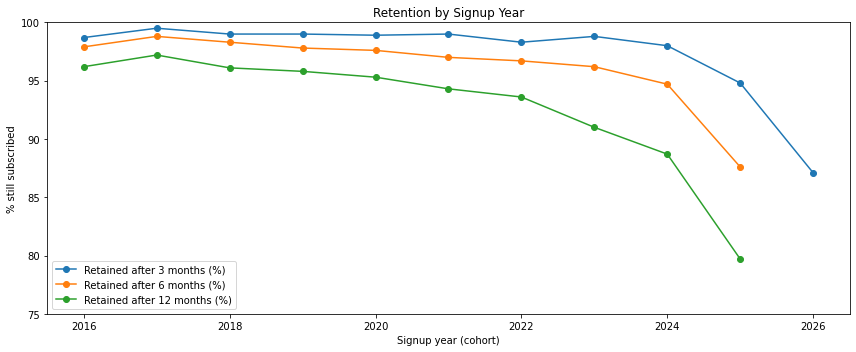

In [15]:
cohort_table.plot(marker="o", figsize=(12, 5))
plt.title("Retention by Signup Year")
plt.xlabel("Signup year (cohort)")
plt.ylabel("% still subscribed")
plt.ylim(75, 100)
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig("kpi_cohort_retention.png", dpi=150)
plt.show()

# Key KPI Findings

| KPI | Value | Target | Status |
|---|---|---|---|
| Active Rate | 74.7% | > 70% | ✅ |
| Churn Rate | 25.3% | < 30% | ✅ |
| Avg Completion Rate | 65.3% | > 60% | ✅ |
| Watchlist Conversion | 46.2% | > 40% | ✅ |

- **All 4 targets were met**: the platform is healthy overall
- **Revenue:** MRR of USD 175,869 from 11,199 active subscribers, with ARPU of USD 15.70
- **Originals perform well:** 21.8% of titles but 27.2% of watch hours
- **Viewing is not over-concentrated:** the top 10% of titles get 31.0% of plays
- **Main risk:** newer subscribers leave faster; 12-month retention fell from about 97% (2017 signups) to 79.7% (2025 signups)
- **Watch point:** churn (25.3%) and active rate (74.7%) are both less than 5 points from their limits